# Quantum reservoir computing in 20 minutes
### Generating a Super Mario level with a photonic circuit (MerLin)

**Audience:** ML practitioners, no quantum background needed.
**Task:** generate Mario level 1-2 one column at a time, using a *frozen* photonic circuit as a feature extractor and a *tiny trained* linear readout.
**Source:** *Level Generation with Quantum Reservoir Computing* (Ferreira et al., [arXiv:2505.13287](https://arxiv.org/abs/2505.13287)).

| Min | Section |
|---:|---|
| 0-3 | The idea: reservoir computing |
| 3-6 | Data and the frozen photonic reservoir |
| 6-10 | Pipeline: memory, features, readout training |
| 10-14 | Generation and the temperature knob |
| 14-18 | Baselines, metrics, and a classical control |
| 18-20 | Takeaways and caveats |

> This is an educational demo, not an exact replication. It does **not** show quantum advantage.

## 1. The idea in one picture

Reservoir computing splits a sequence model into two parts:

```
token x_t ─┐
           ├─► [ FROZEN random nonlinear system ] ─► p_t (20 features) ─► [ trained linear layer ] ─► next token
memory h_t ┘            (here: 3 photons in 6 modes)                          (20 → 32, 672 params)
```

- **Frozen:** the photonic circuit. Never touched by the optimizer. No backprop through it.
- **Trained:** one `Linear(20, 32)` with cross-entropy, as in any classifier.
- **Memory:** an exponential moving average of past features, `h ← (1-ε)h + ε·p`, with ε = 0.3.
- **Generation:** sample the next token with a temperature, feed it back in (autoregressive).

**Why bother?** Interference of photons produces rich nonlinear features cheaply (in simulation here, on photonic hardware in principle), and training stays a convex-ish linear problem.

In [1]:
%pip install -q "merlinquantum>=0.4,<0.5" matplotlib pandas pillow


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /private/tmp/claude-501/demo-venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import base64, io, math, random, time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import merlin as ML
from PIL import Image
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("MerLin", getattr(ML, "__version__", "?"), "| PyTorch", torch.__version__, "| CPU simulation")

MerLin 0.4.1 | PyTorch 2.12.1 | CPU simulation


## 2. Data: a level is a sequence of tokens

Level 1-2 is cut into 16-pixel-wide columns. Each distinct column becomes an integer token: **157 columns, 32 distinct tokens**. Generating a level = next-token prediction, like a very small language model.

In [3]:
# Embedded data (Mario level 1-2, as modified by the paper's authors). Source hidden: it contains an embedded PNG.
ORIGINAL_SEQUENCE = [
    0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 11, 11, 11, 11, 7, 7, 8, 6, 9,
    6, 10, 6, 12, 6, 12, 6, 10, 6, 17, 6, 10, 6, 9, 6, 6, 6, 6, 6,
    22, 15, 22, 20, 20, 22, 15, 31, 6, 6, 6, 6, 6, 23, 23, 26, 26, 6,
    6, 27, 15, 27, 27, 30, 30, 6, 6, 6, 30, 27, 29, 6, 6, 23, 24, 6,
    6, 28, 25, 28, 25, 5, 5, 5, 6, 21, 21, 21, 21, 21, 21, 6, 6, 6,
    6, 6, 6, 6, 6, 6, 7, 7, 6, 7, 13, 14, 6, 6, 6, 6, 18, 19, 6, 6,
    7, 6, 13, 14, 6, 6, 6, 5, 5, 10, 10, 5, 5, 6, 6, 6, 6, 6, 7, 6,
    8, 9, 10, 12, 16, 4, 4, 4, 3, 3, 3, 3, 3, 2, 0, 0, 4, 4, 4, 1,
    1, 1, 1, 1, 1,
]

_LEVEL_PNG_B64 = "..."
ORIGINAL_LEVEL_IMAGE = Image.open(io.BytesIO(base64.b64decode(_LEVEL_PNG_B64))).convert("RGB")


def build_tile_atlas(image, sequence, tile_width=16):
    atlas = {}
    for index, feature in enumerate(sequence):
        if feature not in atlas:
            atlas[feature] = image.crop((index * tile_width, 0, (index + 1) * tile_width, image.height)).copy()
    return atlas

TILE_ATLAS = build_tile_atlas(ORIGINAL_LEVEL_IMAGE, ORIGINAL_SEQUENCE)

def render_level(sequence, atlas=TILE_ATLAS):
    w = next(iter(atlas.values())).width
    h = next(iter(atlas.values())).height
    canvas = Image.new("RGB", (w * len(sequence), h))
    for i, f in enumerate(sequence):
        canvas.paste(atlas[int(f)], (i * w, 0))
    return canvas

157 tokens, 32 distinct
First 20 tokens: [0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 11, 11, 11, 11, 7, 7, 8, 6, 9, 6]


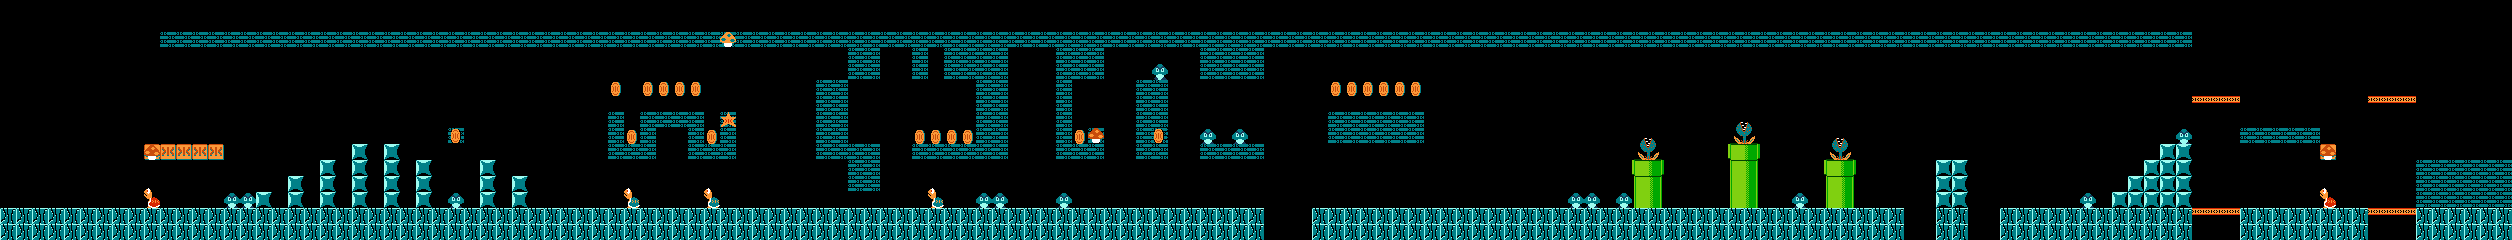

In [4]:
sequence_length, vocabulary_size = len(ORIGINAL_SEQUENCE), len(set(ORIGINAL_SEQUENCE))
print(f"{sequence_length} tokens, {vocabulary_size} distinct")
print("First 20 tokens:", ORIGINAL_SEQUENCE[:20])
display(ORIGINAL_LEVEL_IMAGE)

# Teacher forcing: input = token t, target = token t+1
inputs  = np.asarray(ORIGINAL_SEQUENCE[:-1])
targets = np.asarray(ORIGINAL_SEQUENCE[1:])

## 3. The frozen photonic reservoir (MerLin)

A MerLin `CircuitBuilder` describes an optical circuit; `QuantumLayer` wraps it as a regular `torch.nn.Module`.

| Choice | Value | Consequence |
|---|---:|---|
| Optical modes | 6 | 6 real inputs, encoded as phase shifts |
| Photons | 3 | multi-photon interference |
| Output | probabilities over the C(6,3) = **20** ways to place 3 photons in 6 modes | the feature vector |
| Parameters | random, frozen | `requires_grad=False` |

Circuit: `random interferometer → encode input → interferometer → interferometer → measure`.

In [5]:
N_MODES, N_PHOTONS = 6, 3

def build_merlin_reservoir(n_modes=N_MODES, n_photons=N_PHOTONS):
    builder = ML.CircuitBuilder(n_modes=n_modes)
    builder.add_entangling_layer(trainable=False, name="pre")
    builder.add_angle_encoding(modes=list(range(n_modes)), name="qrc_input", scale=np.pi)
    builder.add_entangling_layer(trainable=False, name="post_1")
    builder.add_entangling_layer(trainable=False, name="post_2")
    layer = ML.QuantumLayer(
        input_size=n_modes, builder=builder, n_photons=n_photons,
        measurement_strategy=ML.MeasurementStrategy.probs(computation_space=ML.ComputationSpace.UNBUNCHED),
        dtype=torch.float64,
    )
    for p in layer.parameters():
        p.requires_grad_(False)          # reservoir = frozen
    return layer.eval()

reservoir = build_merlin_reservoir()
RESERVOIR_DIM = reservoir.output_size

with torch.no_grad():
    probe = reservoir(torch.zeros((1, N_MODES), dtype=torch.float64))

print("Output dim            :", RESERVOIR_DIM, "(expected", math.comb(N_MODES, N_PHOTONS), ")")
print("Sums to 1             :", bool(torch.isclose(probe.sum(), torch.tensor(1.0, dtype=torch.float64))))
print("Trainable parameters  :", sum(p.requires_grad for p in reservoir.parameters()))

Output dim            : 20 (expected 20 )
Sums to 1             : True
Trainable parameters  : 0


### A quick look at what the reservoir does

Sweep one input coordinate and watch the 20 output probabilities. This is the nonlinear, interference-driven feature map the readout will use.

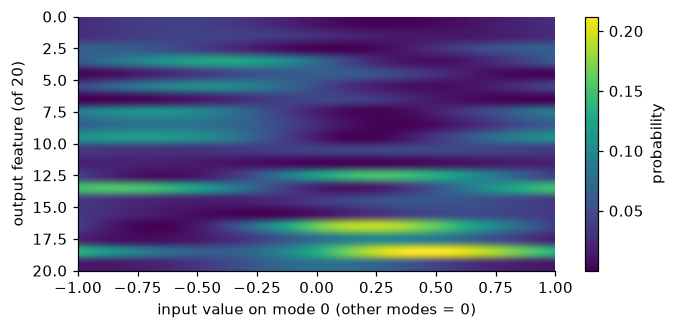

In [6]:
sweep = np.linspace(-1, 1, 200)
batch = np.zeros((len(sweep), N_MODES)); batch[:, 0] = sweep
with torch.no_grad():
    out = reservoir(torch.as_tensor(batch, dtype=torch.float64)).numpy()

fig, ax = plt.subplots(figsize=(7, 3))
im = ax.imshow(out.T, aspect="auto", extent=[-1, 1, RESERVOIR_DIM, 0], cmap="viridis")
ax.set_xlabel("input value on mode 0 (other modes = 0)"); ax.set_ylabel("output feature (of 20)")
fig.colorbar(im, label="probability"); plt.show()

## 4. Feeding the token and the memory

The circuit only accepts **6 real numbers**, but we need to tell it two things: *which token* we are on (one of 32) and *what happened before* (a 20-dimensional memory). Two fixed random pieces bridge that gap. Neither is trained:

- **`feature_book` (32 × 6):** a lookup table giving each token its own random 6-number "address" in the circuit's input space. It is like an embedding table, except it is random and frozen. Without it the circuit could not tell tokens apart, since it has no notion of an integer id.
- **`hidden_projection` (20 × 6):** a random matrix that compresses the 20-dimensional memory down to 6 numbers so it can be added to the token signal. Without it the memory could not enter the circuit, which only has 6 inputs.

`input_t = tanh( feature_book[x_t] + √20 · h_t · P )`  → `p_t = reservoir(input_t)`  → memory update below.

**Memory update:** `h_{t+1} = (1-ε)·h_t + ε·p_t`, with ε = 0.3. This is an exponential moving average. At each step the old memory keeps 70% of its weight and the newest reservoir output enters with 30%. So the contribution of a past step shrinks geometrically (0.3, 0.21, 0.15, ... after 0, 1, 2 steps) but never drops to zero: the memory is a fading summary of the whole history, not just the last token. That is what lets a model with no recurrent weights still depend on context. ε sets the trade-off: a larger ε forgets faster and reacts to the latest token, a smaller ε remembers further back.

In [7]:
class FixedQRCEncoder:
    def __init__(self, num_features, n_modes, reservoir_dim, seed=SEED):
        rng = np.random.default_rng(seed)
        self.feature_book = rng.uniform(-1, 1, size=(num_features, n_modes))
        self.hidden_projection = rng.normal(0, 1, size=(reservoir_dim, n_modes))
        self.reservoir_dim = reservoir_dim

    def __call__(self, token, hidden):
        return np.tanh(self.feature_book[int(token)]
                       + np.sqrt(self.reservoir_dim) * (hidden @ self.hidden_projection))

def update_hidden(hidden, probabilities, epsilon=0.3):
    h = (1 - epsilon) * hidden + epsilon * probabilities
    return h / h.sum()

def reservoir_probabilities(layer, x):
    with torch.no_grad():
        p = layer(torch.as_tensor(x, dtype=torch.float64).unsqueeze(0)).squeeze(0).numpy()
    p = np.clip(p.astype(float), 0, None)
    return p / p.sum()

encoder = FixedQRCEncoder(vocabulary_size, N_MODES, RESERVOIR_DIM)

## 5. Teacher-forced features, then train *only* the readout

Run the true level through the reservoir once (156 sequential steps) to get a `156 × 20` feature matrix. After that, training is ordinary supervised learning on a fixed matrix.

Feature matrix (156, 20) in 0.0s


Trained params: 672 | loss 3.45 → 1.56


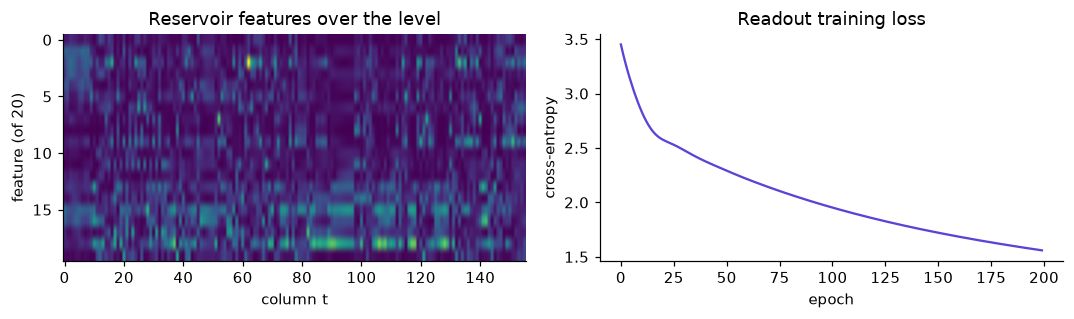

In [8]:
def teacher_forced_features(layer, enc, sequence, epsilon=0.3):
    hidden = np.full(layer.output_size, 1 / layer.output_size)
    feats = []
    for token in sequence[:-1]:
        p = reservoir_probabilities(layer, enc(token, hidden))
        feats.append(p)
        hidden = update_hidden(hidden, p, epsilon)
    return np.asarray(feats)

def train_readout(features, targets, epochs=200, lr=0.05, seed=SEED):
    X = torch.as_tensor(features, dtype=torch.float64)
    y = torch.as_tensor(targets, dtype=torch.long)
    torch.manual_seed(seed)
    readout = torch.nn.Linear(X.shape[1], vocabulary_size, dtype=torch.float64)
    opt = torch.optim.Adam(readout.parameters(), lr=lr)
    history = []
    for _ in range(epochs):
        opt.zero_grad()
        loss = torch.nn.functional.cross_entropy(readout(X), y)
        loss.backward(); opt.step()
        history.append(loss.item())
    return readout.eval(), history

t0 = time.time()
quantum_features = teacher_forced_features(reservoir, encoder, ORIGINAL_SEQUENCE)
print(f"Feature matrix {quantum_features.shape} in {time.time() - t0:.1f}s")

readout, loss_history = train_readout(quantum_features, targets)
print(f"Trained params: {sum(p.numel() for p in readout.parameters())} | "
      f"loss {loss_history[0]:.2f} → {loss_history[-1]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].imshow(quantum_features.T, aspect="auto", cmap="viridis")
axes[0].set(title="Reservoir features over the level", xlabel="column t", ylabel="feature (of 20)")
axes[1].plot(loss_history, color="#5B43D6")
axes[1].set(title="Readout training loss", xlabel="epoch", ylabel="cross-entropy")
plt.tight_layout(); plt.show()

## 6. Generate in a closed loop, with a temperature

At generation time the model feeds its own predictions back in, so mistakes can compound. Temperature `T` rescales the logits before sampling: low `T` is conservative, high `T` is adventurous.

**Predict before running:** what do you expect `T = 0.7, 1.0, 2.0` to do to novelty and to broken transitions? Do both move?

30 levels generated in 0.9s
Original level


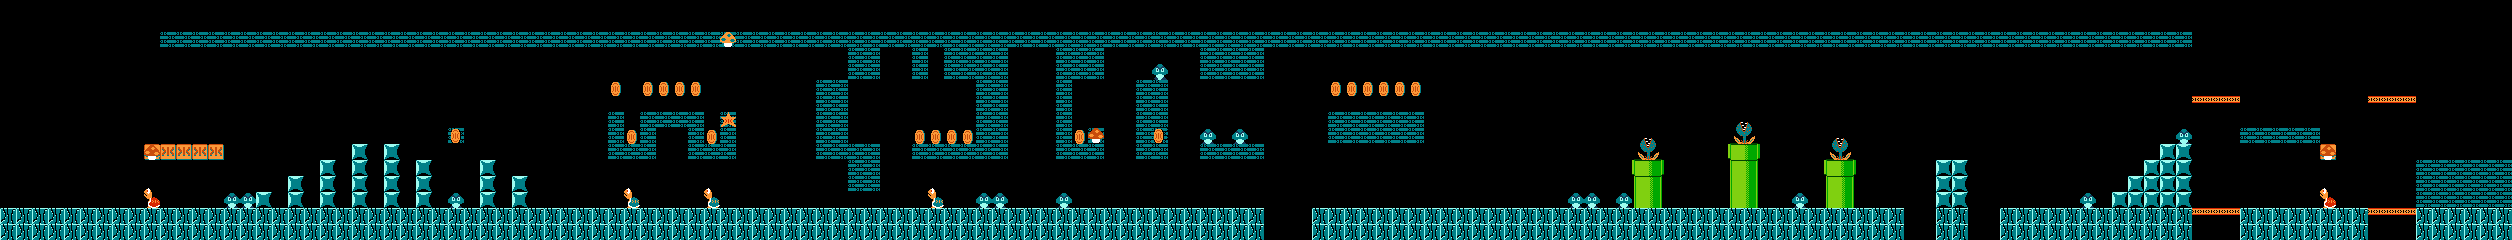

Generated, T = 0.7


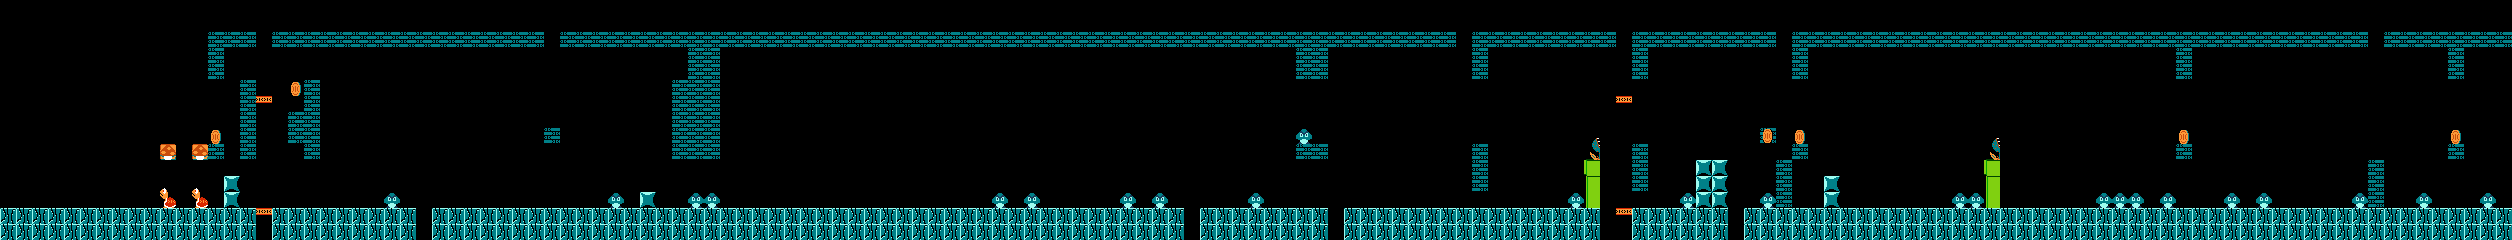

Generated, T = 1.0


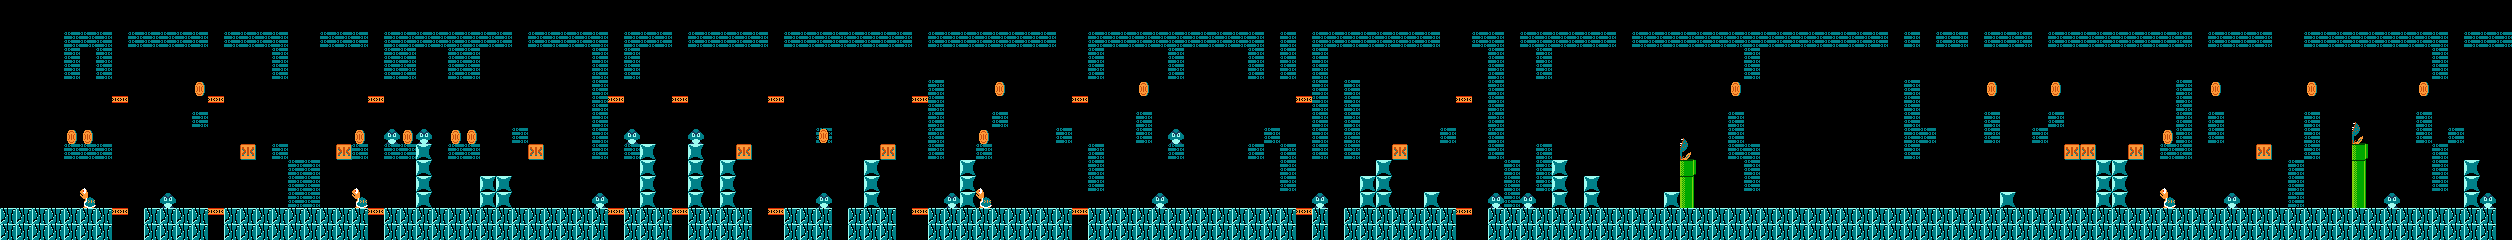

Generated, T = 2.0


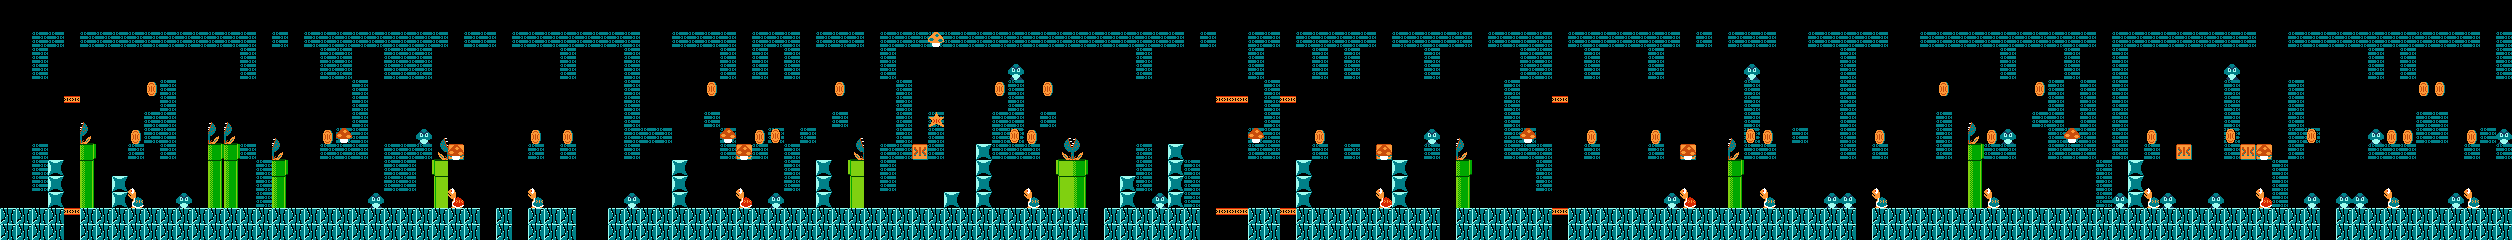

In [9]:
def softmax_temperature(logits, temperature=1.0):
    z = np.asarray(logits, dtype=float) / temperature
    z -= z.max()
    e = np.exp(z)
    return e / e.sum()

def generate_level(layer, enc, readout, length, temperature, seed, epsilon=0.3, first_token=0):
    rng = np.random.default_rng(seed)
    hidden = np.full(layer.output_size, 1 / layer.output_size)
    out = [int(first_token)]
    for _ in range(length - 1):
        p = reservoir_probabilities(layer, enc(out[-1], hidden))
        hidden = update_hidden(hidden, p, epsilon)
        with torch.no_grad():
            logits = readout(torch.as_tensor(p, dtype=torch.float64)).numpy()
        out.append(int(rng.choice(len(logits), p=softmax_temperature(logits, temperature))))
    return out

def generate_many(layer, enc, readout, temperatures, n, tag=0):
    return {T: [generate_level(layer, enc, readout, sequence_length, T,
                               seed=SEED + tag + i + int(100 * T), first_token=ORIGINAL_SEQUENCE[0])
                for i in range(n)] for T in temperatures}

TEMPERATURES = [0.7, 1.0, 2.0]
N_GENERATIONS = 10

t0 = time.time()
qrc_generations = generate_many(reservoir, encoder, readout, TEMPERATURES, N_GENERATIONS)
print(f"{N_GENERATIONS * len(TEMPERATURES)} levels generated in {time.time() - t0:.1f}s")

print("Original level"); display(ORIGINAL_LEVEL_IMAGE)
for T in TEMPERATURES:
    print(f"Generated, T = {T}"); display(render_level(qrc_generations[T][0]))

## 7. Compare against baselines, and score the levels

Two cheap baselines that a practitioner should always run first:

- **Uncorrelated:** samples tokens i.i.d. from their global frequencies.
- **Markov:** samples the next token given only the current one (bigram).

**Metrics**
- **Originality at length L:** fraction of generated L-grams never seen in the original level (higher = more novel).
- **Broken-transition rate:** fraction of applicable Mario rules violated, e.g. a pipe's left half not followed by its right half (lower = more playable).

In [10]:
def fit_markov(sequence):
    transitions = defaultdict(Counter)
    for cur, nxt in zip(sequence[:-1], sequence[1:]):     # no wrap-around
        transitions[int(cur)][int(nxt)] += 1
    return transitions

def generate_uncorrelated(sequence, length, rng):
    vals, counts = np.unique(sequence, return_counts=True)
    return rng.choice(vals, size=length, p=counts / counts.sum()).tolist()

def generate_markov(sequence, length, rng, transitions):
    out = [int(rng.choice(sequence))]
    for _ in range(length - 1):
        c = transitions[out[-1]]
        vals = np.asarray(sorted(c)); p = np.asarray([c[v] for v in vals], float)
        out.append(int(rng.choice(vals, p=p / p.sum())))
    return out

rng = np.random.default_rng(SEED)
markov_T = fit_markov(ORIGINAL_SEQUENCE)
uncorrelated_generations = [generate_uncorrelated(ORIGINAL_SEQUENCE, sequence_length, rng) for _ in range(100)]
markov_generations = [generate_markov(ORIGINAL_SEQUENCE, sequence_length, rng, markov_T) for _ in range(100)]

def count_ngrams(seq, n):
    return Counter(tuple(seq[i:i + n]) for i in range(len(seq) - n + 1))

def originality(generated, original, n):
    orig = count_ngrams(original, n); novel = total = 0
    for g in generated:
        for ng, c in count_ngrams(g, n).items():
            total += c; novel += c * (ng not in orig)
    return novel / total

def mario_rule_2(i, s):
    if i <= 0 or i >= len(s) - 1: return None
    f, a, b = int(s[i]), int(s[i - 1]), int(s[i + 1])
    if f == 14: return a == 13          # right half of small pipe
    if f == 13: return b == 14          # left half of small pipe
    if f == 19: return a == 18          # right half of large pipe
    if f == 18: return b == 19          # left half of large pipe
    if f == 30: return a not in {1, 10, 12, 16, 18, 19} and b not in {1, 10, 12, 16, 18, 19}  # free passage
    return None

def broken_rate(seq):
    r = [x for x in (mario_rule_2(i, seq) for i in range(len(seq))) if x is not None]
    return 1 - float(np.mean(r)) if r else np.nan

def score(label, gens, T=np.nan):
    return {"generator": label, "T": T,
            "originality L=2": originality(gens, ORIGINAL_SEQUENCE, 2),
            "originality L=10": originality(gens, ORIGINAL_SEQUENCE, 10),
            "broken rate": float(np.nanmean([broken_rate(g) for g in gens]))}

rows = [score("Original level", [ORIGINAL_SEQUENCE]),
        score("Uncorrelated", uncorrelated_generations),
        score("Markov", markov_generations)]
rows += [score("QRC (MerLin)", qrc_generations[T], T) for T in TEMPERATURES]
results = pd.DataFrame(rows).round(3)
results

,generator,T,originality L=2,originality L=10,broken rate
0,Original level,NaN,0.000,0.000,0.000
1,Uncorrelated,NaN,0.625,1.000,0.746
2,Markov,NaN,0.000,0.997,0.000
3,QRC (MerLin),0.7,0.269,0.983,0.737
4,QRC (MerLin),1.0,0.535,0.999,0.722
5,QRC (MerLin),2.0,0.791,1.000,0.787


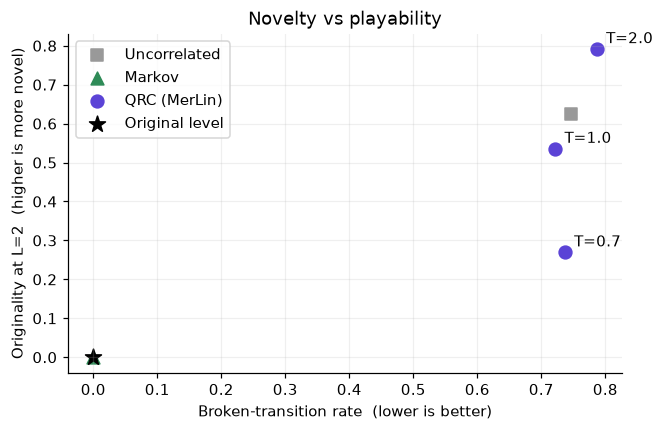

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4))
styles = {"Uncorrelated": ("#999999", "s"), "Markov": ("#2E8B57", "^"), "QRC (MerLin)": ("#5B43D6", "o")}
for _, r in results.iterrows():
    if r["generator"] in styles:
        color, marker = styles[r["generator"]]
        ax.scatter(r["broken rate"], r["originality L=2"], c=color, marker=marker, s=70, label=r["generator"])
        if r["generator"] == "QRC (MerLin)":
            ax.annotate(f"T={r['T']}", (r["broken rate"], r["originality L=2"]), xytext=(6, 4), textcoords="offset points")
ax.scatter(results.iloc[0]["broken rate"], results.iloc[0]["originality L=2"], c="k", marker="*", s=120, label="Original level")
h, l = ax.get_legend_handles_labels(); ax.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys())
ax.set(xlabel="Broken-transition rate  (lower is better)", ylabel="Originality at L=2  (higher is more novel)",
       title="Novelty vs playability")
ax.grid(alpha=.2); plt.show()

## 8. Control experiment: does the *photonic* part matter?

Good practice: swap the frozen quantum circuit for a frozen **classical** random feature map with the same interface (6 → 20 probabilities) and rerun the identical pipeline.

In [12]:
class RandomClassicalReservoir(torch.nn.Module):
    """Frozen random 6 -> 20 map, softmax-normalised so outputs are probability vectors."""
    def __init__(self, n_in=N_MODES, n_out=RESERVOIR_DIM, seed=SEED):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        self.register_buffer("W", torch.randn(n_in, n_out, generator=g, dtype=torch.float64) * 3.0)
        self.output_size = n_out
    def forward(self, x):
        return torch.softmax(torch.tanh(x @ self.W) * 3.0, dim=-1)

classical = RandomClassicalReservoir()
c_feats = teacher_forced_features(classical, encoder, ORIGINAL_SEQUENCE)
c_readout, c_loss = train_readout(c_feats, targets)
c_gens = generate_many(classical, encoder, c_readout, TEMPERATURES, N_GENERATIONS, tag=1000)

control = pd.DataFrame(
    [{"reservoir": "Photonic (MerLin)", "final train loss": loss_history[-1]}
     | {f"broken T={T}": score("", qrc_generations[T])["broken rate"] for T in TEMPERATURES},
     {"reservoir": "Classical random", "final train loss": c_loss[-1]}
     | {f"broken T={T}": score("", c_gens[T])["broken rate"] for T in TEMPERATURES}]).round(3)
control

,reservoir,final train loss,broken T=0.7,broken T=1.0,broken T=2.0
0,Photonic (MerLin),1.560,0.737,0.722,0.787
1,Classical random,1.863,0.611,0.761,0.814


## 9. Takeaways

**What you saw**
- A MerLin `QuantumLayer` is a drop-in, frozen `torch.nn.Module`: 6 inputs → 20 probabilities.
- Only 672 parameters were trained, with ordinary Adam and cross-entropy.
- Temperature mainly moves **novelty** (originality at L=2 rises with T). In this run the **broken-transition rate stays high (~0.7-0.8)**, close to the uncorrelated baseline, while Markov is fully coherent but copies the level. So this small QRC does **not** beat the simple baselines on playability.
- The classical random reservoir fits the training data slightly worse here (higher loss); its broken rates are in the same range. With one seed this is not a conclusion either way.

**Caveats (read before quoting any number)**
- Ten levels per temperature and one random reservoir seed: results are indicative, not statistical. Rerun with more levels and several seeds before drawing conclusions.
- The readout is a plain linear layer on 20 features and underfits (final loss ~1.6); that limits coherence.
- The classical control is one simple choice of classical reservoir: a sanity check, not a rigorous comparison.
- Simulated on a CPU; no hardware, no noise, no quantum-advantage claim.
- Numbers differ from the paper (6-mode photonic translation vs the paper's qubit reservoir).

**Next steps**
- Increase `N_GENERATIONS` to 20+ and loop over `SEED`; report mean ± std.
- Vary photons/modes (reservoir dimension) and ε.
- Compare with the qubit-based reproduction and with a classical echo-state network.

**References:** Ferreira et al., arXiv:2505.13287 · MerLin documentation · original 2-hour workshop notebook by the same repository authors.